# NEURO/LAB — Brain MRI classification and tumor-region segmentation

**Full training and analysis notebook** for the local BRISC 2025 v3 project. It loads the prepared manifest, explores and audits the data, trains every architecture used by this project, compares validation results, visualizes predictions, evaluates each fixed model candidate once on the held-out test split, and saves model packages and reports.

## Model zoo in this notebook

| Task | Models trained | Main output |
|---|---|---|
| Four-class MRI classification | MobileNetV3-Small | Scores for glioma, meningioma, no tumor, and pituitary |
| Binary region segmentation | Compact U-Net baseline | Pixel-level tumor-region mask |
| Binary region segmentation | Residual Attention U-Net | Pixel-level tumor-region mask |

The classifier and segmenter are separate models. A segmentation mask is not a tumor subtype or a diagnosis. Grad-CAM is a coarse feature-attribution visualization, not an explanation of cause.

> **Research use only.** The BRISC manifest has no patient identifiers. Exact decoded-image duplicates were audited, but patient-level independence and performance on other hospitals/scanners cannot be established. Keep the test split out of training, threshold selection, and model selection.

### Recommended run order

Run the notebook from the `D:\BTS` project folder, using its `.venv` Python kernel. Execute cells from top to bottom. Training can take a long time on CPU; use a CUDA-enabled PyTorch install and reduce the training settings below if GPU memory is limited. Training writes new versioned outputs under `notebooks/outputs/` and does not replace the app's active checkpoints.

## 1. Environment setup

In VS Code, open `D:\BTS`, install the **Python** and **Jupyter** extensions, then choose the interpreter at `.venv\Scripts\python.exe` for this notebook. In a project terminal, run:

```powershell
.venv\Scripts\python.exe -m pip install -r notebooks\requirements-notebook.txt
```

PyTorch and torchvision are installed separately so you can choose a build compatible with your NVIDIA CUDA driver. The project's `.venv` already includes them. If setting up a different environment, use the official PyTorch installation selector and install a matching `torch`/`torchvision` pair first. Then select the same environment as the notebook kernel.

In [1]:
import os
import sys
import json
import math
import random
import hashlib
import platform
from datetime import datetime
from pathlib import Path, PureWindowsPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_recall_fscore_support, roc_auc_score, roc_curve, auc,
)

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import mobilenet_v3_small

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0], "| Platform:", platform.platform())
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.14.0 | Platform: Windows-11-10.0.26200-SP0
PyTorch: 2.14.1+cu130 | CUDA available: True | Device: cuda
GPU: NVIDIA GeForce RTX 3050 A Laptop GPU


In [2]:
def find_project_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for candidate in (here, *here.parents):
        if (candidate / "backend" / "training" / "data.py").is_file() and (candidate / "data" / "manifests").is_dir():
            return candidate
    raise FileNotFoundError("Open this notebook inside the NEURO/LAB project so its project root can be found.")

PROJECT_ROOT = find_project_root()
MANIFEST_PATH = PROJECT_ROOT / "data" / "manifests" / "brisc.csv"
DATASET_ROOT = PROJECT_ROOT / "data" / "datasets" / "brisc2025"
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_DIR = PROJECT_ROOT / "notebooks" / "outputs" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

# Training controls. Lower batch size / image size / epoch count for a small GPU or CPU.
SEED = 29
CLASSIFIER_SIZE = 224
CLASSIFIER_BATCH_SIZE = 16
CLASSIFIER_EPOCHS = 10
CLASSIFIER_LR = 5e-4
SEGMENTATION_SIZE = 256
SEGMENTATION_BATCH_SIZE = 4
SEGMENTATION_EPOCHS = 20
SEGMENTATION_PATIENCE = 7
SEGMENTATION_LR = 4e-4
NUM_WORKERS = 0  # Safe default for Windows notebooks.
USE_HORIZONTAL_FLIP_TTA = True

print("Project:", PROJECT_ROOT)
print("Manifest:", MANIFEST_PATH, "| exists:", MANIFEST_PATH.is_file())
print("New outputs:", RUN_DIR)

Project: D:\BTS
Manifest: D:\BTS\data\manifests\brisc.csv | exists: True
New outputs: D:\BTS\notebooks\outputs\20261027_213449_214091


In [3]:
def resolve_manifest_path(value):
    # Reuse a recorded path where possible; otherwise rebase dataset-relative suffixes to this checkout.
    if value is None or (isinstance(value, float) and np.isnan(value)) or not str(value).strip():
        return ""
    raw = str(value).strip()
    direct = Path(raw)
    if direct.is_file():
        return str(direct.resolve())
    portable = raw.replace("\\", "/")
    parts = [part for part in portable.split("/") if part]
    lowered = [part.lower() for part in parts]
    for anchor in ("classification_task", "segmentation_task"):
        if anchor in lowered:
            index = lowered.index(anchor)
            candidate = DATASET_ROOT.joinpath(*parts[index:])
            if candidate.is_file():
                return str(candidate.resolve())
    if "data" in lowered and "datasets" in lowered:
        index = lowered.index("data")
        candidate = PROJECT_ROOT.joinpath(*parts[index:])
        if candidate.is_file():
            return str(candidate.resolve())
    if not direct.is_absolute():
        candidate = PROJECT_ROOT / direct
        if candidate.is_file():
            return str(candidate.resolve())
    return str(direct)

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Prepared manifest not found: {MANIFEST_PATH}. See the dataset setup notes at the end of this notebook.")

df = pd.read_csv(MANIFEST_PATH)
required = {"image_path", "mask_path", "label", "split"}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing required columns: {sorted(missing_columns)}")

df["image_path"] = df["image_path"].map(resolve_manifest_path)
df["mask_path"] = df["mask_path"].map(resolve_manifest_path)
df["mask_path"] = df["mask_path"].fillna("")
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["split"] = df["split"].astype(str).str.strip().str.lower()
classes = ["glioma", "meningioma", "no_tumor", "pituitary"]
expected_splits = {"train", "validation", "test"}

bad_labels = sorted(set(df["label"]) - set(classes))
bad_splits = sorted(set(df["split"]) - expected_splits)
missing_images = df.loc[~df["image_path"].map(lambda p: Path(p).is_file()), "image_path"].head(10).tolist()
missing_masks = df.loc[df["mask_path"].ne("") & ~df["mask_path"].map(lambda p: Path(p).is_file()), "mask_path"].head(10).tolist()
if bad_labels or bad_splits or missing_images or missing_masks:
    raise ValueError(f"Manifest audit failed. Unknown labels={bad_labels}; unknown splits={bad_splits}; missing image examples={missing_images}; missing mask examples={missing_masks}")

print(f"Rows: {len(df):,} | matched masks: {(df['mask_path'] != '').sum():,}")
print("Unique labels:", sorted(df["label"].unique()))
print("Split totals:\n", df["split"].value_counts().reindex(["train", "validation", "test"]))
display(df.head())

Rows: 5,856 | matched masks: 4,659
Unique labels: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Split totals:
 split
train         4134
validation     730
test           992
Name: count, dtype: int64


,image_path,mask_path,label,split
0,D:\BTS\data\datasets\brisc2025\classification_...,D:\BTS\data\datasets\brisc2025\segmentation_ta...,glioma,test
1,D:\BTS\data\datasets\brisc2025\classification_...,D:\BTS\data\datasets\brisc2025\segmentation_ta...,glioma,test
2,D:\BTS\data\datasets\brisc2025\classification_...,D:\BTS\data\datasets\brisc2025\segmentation_ta...,glioma,test
3,D:\BTS\data\datasets\brisc2025\classification_...,D:\BTS\data\datasets\brisc2025\segmentation_ta...,glioma,test
4,D:\BTS\data\datasets\brisc2025\classification_...,D:\BTS\data\datasets\brisc2025\segmentation_ta...,glioma,test


## 2. Dataset exploration and visualization

The prepared manifest points to one 2D image per row. Tumor labels are image-level labels; a matched mask provides a binary tumor-region target. No-tumor images without masks are used as empty-mask examples during segmentation training. The three existing splits are preserved.

In [4]:
class_counts = df.groupby(["label", "split"]).size().rename("images").reset_index()
fig = px.bar(class_counts, x="label", y="images", color="split", barmode="group",
             category_orders={"label": classes, "split": ["train", "validation", "test"]},
             title="BRISC image counts by class and split", text_auto=True)
fig.update_layout(xaxis_title="Image-level class", yaxis_title="Images", legend_title="Split")
fig.show()

split_summary = df.groupby("split").agg(images=("image_path", "size"), classes=("label", "nunique"))
split_summary["matched_masks"] = df.assign(has_mask=df["mask_path"].ne("")).groupby("split")["has_mask"].sum()
display(split_summary.reindex(["train", "validation", "test"]))

,images,classes,matched_masks
split,,,
train,4134,4,3235
validation,730,4,571
test,992,4,853


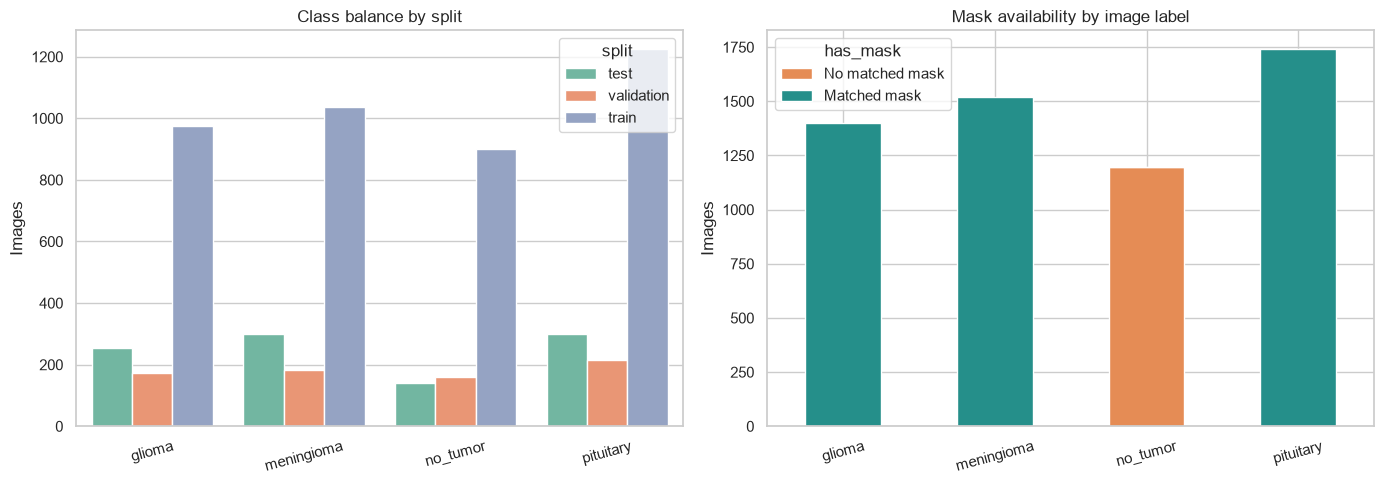

In [5]:
mask_summary = df.assign(has_mask=df["mask_path"].ne("")).groupby(["label", "split", "has_mask"]).size().rename("images").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="label", hue="split", order=classes, ax=axes[0])
axes[0].set_title("Class balance by split"); axes[0].set_xlabel(""); axes[0].set_ylabel("Images"); axes[0].tick_params(axis="x", rotation=15)
mask_by_class = df.assign(has_mask=df["mask_path"].ne("")).groupby(["label", "has_mask"]).size().unstack(fill_value=0).reindex(classes)
mask_by_class.rename(columns={False: "No matched mask", True: "Matched mask"}).plot(kind="bar", stacked=True, ax=axes[1], color=["#e58c55", "#258f8a"])
axes[1].set_title("Mask availability by image label"); axes[1].set_xlabel(""); axes[1].set_ylabel("Images"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

In [6]:
def decoded_rgb_sha256(path):
    with Image.open(path) as image:
        rgb = image.convert("RGB")
        digest = hashlib.sha256()
        digest.update(rgb.width.to_bytes(4, "big")); digest.update(rgb.height.to_bytes(4, "big"))
        digest.update(rgb.tobytes())
        return digest.hexdigest()

hashes = []
for image_path in tqdm(df["image_path"], desc="Auditing exact decoded-pixel duplicates"):
    hashes.append(decoded_rgb_sha256(image_path))
df["decoded_rgb_sha256"] = hashes
duplicate_groups = df.groupby("decoded_rgb_sha256").agg(rows=("image_path", "size"), labels=("label", "nunique"), splits=("split", "nunique"))
cross_split_duplicates = duplicate_groups.query("splits > 1")
conflicting_label_duplicates = duplicate_groups.query("labels > 1")
print(f"Rows={len(df):,}; distinct decoded images={df['decoded_rgb_sha256'].nunique():,}")
print(f"Exact duplicate groups crossing splits={len(cross_split_duplicates)}")
print(f"Exact duplicate groups with conflicting labels={len(conflicting_label_duplicates)}")
if len(cross_split_duplicates):
    display(df[df["decoded_rgb_sha256"].isin(cross_split_duplicates.index)].sort_values("decoded_rgb_sha256").head(20))
else:
    print("No exact decoded-image duplicates cross the prepared train/validation/test split.")
print("Limitation: matching pixels does not establish patient-level separation or exclude near-duplicates.")

Auditing exact decoded-pixel duplicates:   0%|          | 0/5856 [00:00<?, ?it/s]

Rows=5,856; distinct decoded images=5,856
Exact duplicate groups crossing splits=0
Exact duplicate groups with conflicting labels=0
No exact decoded-image duplicates cross the prepared train/validation/test split.
Limitation: matching pixels does not establish patient-level separation or exclude near-duplicates.


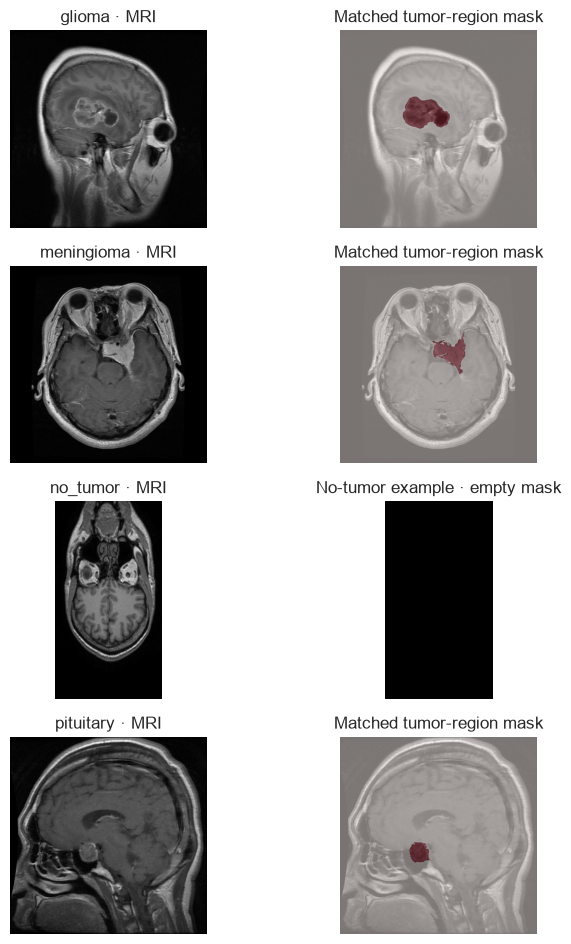

In [7]:
def show_image_mask_gallery(dataframe, per_class=2, split="train", seed=SEED):
    subset = dataframe[dataframe["split"].eq(split)]
    samples = []
    for label in classes:
        group = subset[subset["label"].eq(label)]
        if len(group):
            samples.extend(group.sample(min(per_class, len(group)), random_state=seed).to_dict("records"))
    fig, axes = plt.subplots(len(samples), 2, figsize=(8, max(3, 2.4 * len(samples))), squeeze=False)
    for row_index, row in enumerate(samples):
        image = Image.open(row["image_path"]).convert("RGB")
        axes[row_index, 0].imshow(image); axes[row_index, 0].set_title(f"{row['label']} · MRI")
        axes[row_index, 0].axis("off")
        if row["mask_path"] and Path(row["mask_path"]).is_file():
            mask = Image.open(row["mask_path"]).convert("L")
            axes[row_index, 1].imshow(image); axes[row_index, 1].imshow(mask, cmap="Reds", alpha=0.48)
            axes[row_index, 1].set_title("Matched tumor-region mask")
        else:
            axes[row_index, 1].imshow(np.zeros((image.height, image.width)), cmap="gray", vmin=0, vmax=1)
            axes[row_index, 1].set_title("No-tumor example · empty mask")
        axes[row_index, 1].axis("off")
    plt.tight_layout(); plt.show()

show_image_mask_gallery(df, per_class=1, split="train")

## 3. Preprocessing and model inputs

Classification images are resized to 224×224. Segmentation images and masks are resized to 256×256; masks use nearest-neighbor interpolation so they remain discrete. Both networks use RGB images normalized with ImageNet channel statistics. Spatial augmentation for segmentation is applied identically to each image and its mask.

Classification rows: train=4,134, validation=730, test=992
Segmentation rows:   train=4,134, validation=730, test=992


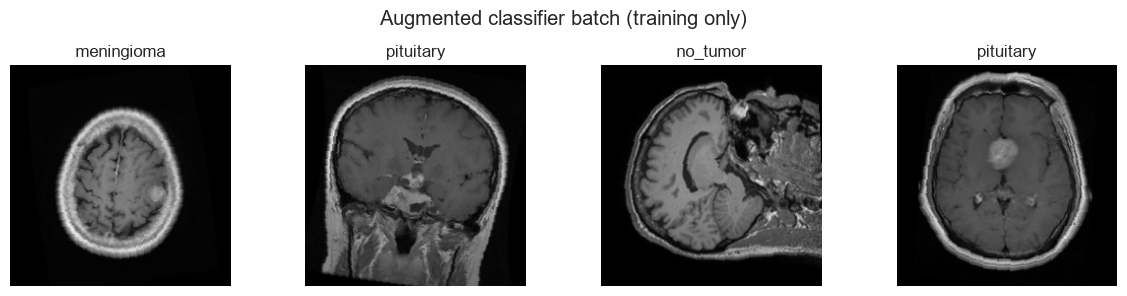

In [8]:
sys.path.insert(0, str(PROJECT_ROOT))
from backend.training.data import (
    CLASSES, ClassificationDataset, SegmentationDataset, LABEL_TO_INDEX,
)
from backend.app.models import (
    build_compact_unet, build_attention_unet, predict_segmentation_probability,
)
def rows_for(split):
    return df.loc[df["split"].eq(split), ["image_path", "mask_path", "label", "split"]].to_dict("records")

train_rows, val_rows, test_rows = (rows_for(name) for name in ("train", "validation", "test"))
train_cls = ClassificationDataset(train_rows, train=True, size=CLASSIFIER_SIZE)
val_cls = ClassificationDataset(val_rows, train=False, size=CLASSIFIER_SIZE)
test_cls = ClassificationDataset(test_rows, train=False, size=CLASSIFIER_SIZE)
train_seg = SegmentationDataset(train_rows, train=True, size=SEGMENTATION_SIZE)
val_seg = SegmentationDataset(val_rows, train=False, size=SEGMENTATION_SIZE)
test_seg = SegmentationDataset(test_rows, train=False, size=SEGMENTATION_SIZE)

generator = torch.Generator().manual_seed(SEED)
loader_options = {"num_workers": NUM_WORKERS, "pin_memory": DEVICE.type == "cuda"}
train_cls_loader = DataLoader(train_cls, batch_size=CLASSIFIER_BATCH_SIZE, shuffle=True, generator=generator, **loader_options)
val_cls_loader = DataLoader(val_cls, batch_size=CLASSIFIER_BATCH_SIZE, shuffle=False, **loader_options)
test_cls_loader = DataLoader(test_cls, batch_size=CLASSIFIER_BATCH_SIZE, shuffle=False, **loader_options)
train_seg_loader = DataLoader(train_seg, batch_size=SEGMENTATION_BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_options)
val_seg_loader = DataLoader(val_seg, batch_size=SEGMENTATION_BATCH_SIZE, shuffle=False, **loader_options)
test_seg_loader = DataLoader(test_seg, batch_size=SEGMENTATION_BATCH_SIZE, shuffle=False, **loader_options)

print(f"Classification rows: train={len(train_cls):,}, validation={len(val_cls):,}, test={len(test_cls):,}")
print(f"Segmentation rows:   train={len(train_seg):,}, validation={len(val_seg):,}, test={len(test_seg):,}")
images, labels = next(iter(train_cls_loader))
fig, axes = plt.subplots(1, min(4, len(images)), figsize=(12, 3))
axes = np.atleast_1d(axes)
mean = torch.tensor([.485, .456, .406]).view(3, 1, 1)
std = torch.tensor([.229, .224, .225]).view(3, 1, 1)
for ax, image, label in zip(axes, images, labels):
    shown = (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(shown); ax.set_title(CLASSES[int(label)]); ax.axis("off")
plt.suptitle("Augmented classifier batch (training only)"); plt.tight_layout(); plt.show()

## 4. Architecture overview

The classifier produces four scores for the full image. The compact U-Net and residual Attention U-Net produce one foreground score per pixel. The Attention U-Net uses residual encoder/decoder blocks and attention gates on skip connections; this can help the decoder prioritize spatial features, but does not guarantee a correct mask.

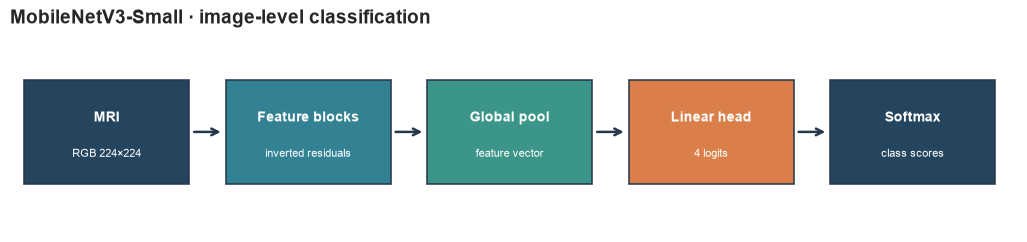

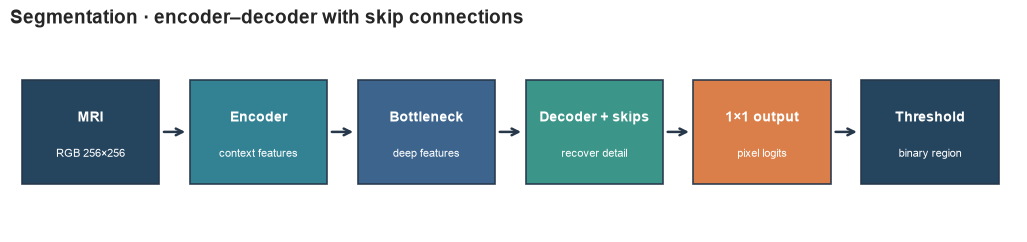

,Task,Architecture,Trainable parameters
0,Classification,MobileNetV3-Small,"1,521,956"
1,Segmentation,Compact U-Net,"117,361"
2,Segmentation,Residual Attention U-Net,"2,051,789"


In [9]:
def draw_pipeline(title, boxes, colors):
    fig, ax = plt.subplots(figsize=(13, 2.6)); ax.set_xlim(0, len(boxes)); ax.set_ylim(0, 1); ax.axis("off")
    for i, (label, detail) in enumerate(boxes):
        ax.add_patch(plt.Rectangle((i + .07, .24), .82, .52, facecolor=colors[i % len(colors)], edgecolor="#26384a", linewidth=1.2, alpha=.95))
        ax.text(i + .48, .57, label, ha="center", va="center", color="white", fontsize=10, weight="bold", wrap=True)
        ax.text(i + .48, .39, detail, ha="center", va="center", color="white", fontsize=8, wrap=True)
        if i < len(boxes) - 1:
            ax.annotate("", xy=(i + 1.06, .5), xytext=(i + .9, .5), arrowprops={"arrowstyle": "->", "lw": 1.8, "color": "#26384a"})
    ax.set_title(title, fontsize=14, weight="bold", loc="left"); plt.show()

draw_pipeline("MobileNetV3-Small · image-level classification", [
    ("MRI", "RGB 224×224"), ("Feature blocks", "inverted residuals"), ("Global pool", "feature vector"), ("Linear head", "4 logits"), ("Softmax", "class scores")
], ["#193b56", "#287b8e", "#318f83", "#d97840"])
draw_pipeline("Segmentation · encoder–decoder with skip connections", [
    ("MRI", "RGB 256×256"), ("Encoder", "context features"), ("Bottleneck", "deep features"), ("Decoder + skips", "recover detail"), ("1×1 output", "pixel logits"), ("Threshold", "binary region")
], ["#193b56", "#287b8e", "#315c87", "#318f83", "#d97840"])

def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

model_rows = []
probe = mobilenet_v3_small(weights=None); probe.classifier[-1] = nn.Linear(probe.classifier[-1].in_features, len(CLASSES))
model_rows.append({"Task": "Classification", "Architecture": "MobileNetV3-Small", "Trainable parameters": parameter_count(probe)})
for name, builder in [("Compact U-Net", build_compact_unet), ("Residual Attention U-Net", build_attention_unet)]:
    model_rows.append({"Task": "Segmentation", "Architecture": name, "Trainable parameters": parameter_count(builder())})
display(pd.DataFrame(model_rows).style.format({"Trainable parameters": "{:,.0f}"}))

## 5. Train the classifier

The classifier is trained from random initialization (no pretrained downloads) with cross-entropy and AdamW. The checkpoint is selected using **validation accuracy only**. The held-out test split is not used here.

In [10]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
classifier = mobilenet_v3_small(weights=None)
classifier.classifier[-1] = nn.Linear(classifier.classifier[-1].in_features, len(CLASSES))
classifier = classifier.to(DEVICE)
optimizer_cls = torch.optim.AdamW(classifier.parameters(), lr=CLASSIFIER_LR)
criterion_cls = nn.CrossEntropyLoss()
scaler_cls = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

def collect_classification_outputs(model, loader):
    model.eval(); all_labels, all_probabilities, total_loss, count = [], [], 0.0, 0
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True); labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            total_loss += float(criterion_cls(logits, labels)) * len(labels); count += len(labels)
            all_labels.extend(labels.cpu().tolist())
            all_probabilities.extend(torch.softmax(logits, dim=1).cpu().numpy())
    probs = np.asarray(all_probabilities)
    return np.asarray(all_labels), probs, total_loss / max(count, 1)

history_classifier = []
best_val_accuracy = -1.0
best_classifier_state = None
for epoch in range(CLASSIFIER_EPOCHS):
    classifier.train(); running_loss = 0.0
    for images, labels in tqdm(train_cls_loader, desc=f"Classifier epoch {epoch + 1}/{CLASSIFIER_EPOCHS}", leave=False):
        images = images.to(DEVICE, non_blocking=True); labels = labels.to(DEVICE, non_blocking=True)
        optimizer_cls.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits = classifier(images); loss = criterion_cls(logits, labels)
        scaler_cls.scale(loss).backward(); scaler_cls.step(optimizer_cls); scaler_cls.update()
        running_loss += float(loss.detach())
    val_labels, val_probs, val_loss = collect_classification_outputs(classifier, val_cls_loader)
    val_pred = val_probs.argmax(axis=1)
    val_accuracy = accuracy_score(val_labels, val_pred)
    val_macro_f1 = f1_score(val_labels, val_pred, average="macro", zero_division=0)
    record = {"epoch": epoch + 1, "train_loss": running_loss / max(len(train_cls_loader), 1),
              "validation_loss": val_loss, "validation_accuracy": val_accuracy, "validation_macro_f1": val_macro_f1}
    history_classifier.append(record)
    print(f"epoch {epoch + 1:02d}/{CLASSIFIER_EPOCHS} | train loss {record['train_loss']:.4f} | val loss {val_loss:.4f} | val accuracy {val_accuracy:.4f} | val macro-F1 {val_macro_f1:.4f}")
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_classifier_state = {key: value.detach().cpu().clone() for key, value in classifier.state_dict().items()}

if best_classifier_state is None:
    raise RuntimeError("Classifier training did not produce a validation checkpoint.")
classifier.load_state_dict(best_classifier_state)
classifier.to(DEVICE)

Classifier epoch 1/10:   0%|          | 0/259 [00:00<?, ?it/s]

epoch 01/10 | train loss 0.7370 | val loss 1.5618 | val accuracy 0.2507 | val macro-F1 0.1002


Classifier epoch 2/10:   0%|          | 0/259 [00:00<?, ?it/s]

epoch 02/10 | train loss 0.4589 | val loss 1.8093 | val accuracy 0.4904 | val macro-F1 0.3479


Classifier epoch 3/10:   0%|          | 0/259 [00:00<?, ?it/s]

...

Classifier epoch 9/10:   0%|          | 0/259 [00:00<?, ?it/s]

epoch 09/10 | train loss 0.1572 | val loss 0.9139 | val accuracy 0.6959 | val macro-F1 0.6849


Classifier epoch 10/10:   0%|          | 0/259 [00:00<?, ?it/s]

epoch 10/10 | train loss 0.1236 | val loss 3.3774 | val accuracy 0.2589 | val macro-F1 0.2536


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16

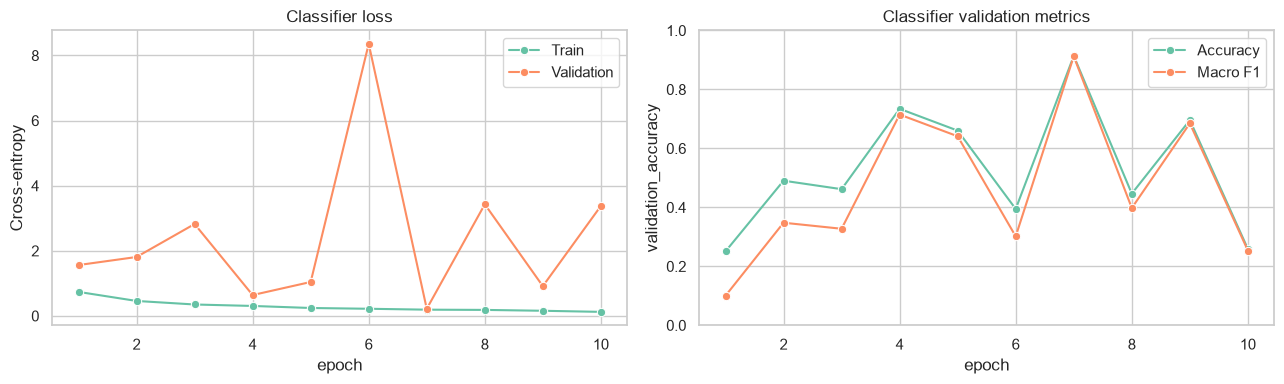

,epoch,train_loss,validation_loss,validation_accuracy,validation_macro_f1
5,6,0.218784,8.355950,0.394521,0.301542
6,7,0.191124,0.218240,0.913699,0.912327
7,8,0.183886,3.427993,0.446575,0.397742
8,9,0.157186,0.913904,0.695890,0.684887
9,10,0.123555,3.377433,0.258904,0.253574


Best classifier checkpoint selected by validation accuracy: 0.9137


In [11]:
history_cls_df = pd.DataFrame(history_classifier)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=history_cls_df, x="epoch", y="train_loss", marker="o", label="Train", ax=axes[0])
sns.lineplot(data=history_cls_df, x="epoch", y="validation_loss", marker="o", label="Validation", ax=axes[0])
axes[0].set_title("Classifier loss"); axes[0].set_ylabel("Cross-entropy")
sns.lineplot(data=history_cls_df, x="epoch", y="validation_accuracy", marker="o", label="Accuracy", ax=axes[1])
sns.lineplot(data=history_cls_df, x="epoch", y="validation_macro_f1", marker="o", label="Macro F1", ax=axes[1])
axes[1].set_title("Classifier validation metrics"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()
display(history_cls_df.tail())
print(f"Best classifier checkpoint selected by validation accuracy: {best_val_accuracy:.4f}")

              precision    recall  f1-score   support

      glioma     0.8730    0.9593    0.9141       172
  meningioma     0.9481    0.7978    0.8665       183
    no_tumor     0.8914    0.9811    0.9341       159
   pituitary     0.9434    0.9259    0.9346       216

    accuracy                         0.9137       730
   macro avg     0.9140    0.9160    0.9123       730
weighted avg     0.9167    0.9137    0.9126       730



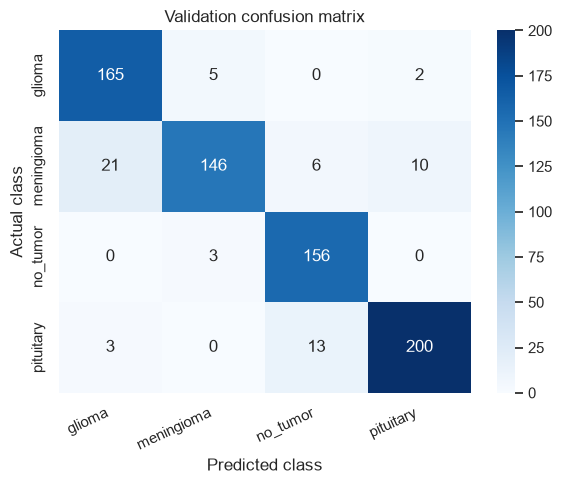

In [12]:
val_labels, val_probs, _ = collect_classification_outputs(classifier, val_cls_loader)
val_predictions = val_probs.argmax(axis=1)
print(classification_report(val_labels, val_predictions, labels=range(len(CLASSES)), target_names=CLASSES, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion_matrix(val_labels, val_predictions, labels=range(len(CLASSES))), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(title="Validation confusion matrix", xlabel="Predicted class", ylabel="Actual class")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

### Grad-CAM: where did the classifier obtain image features?

Grad-CAM uses gradients at the last convolutional feature block to create a coarse heatmap for a chosen class score. It highlights image regions that influenced that score in this model; it is not a tumor mask, causal explanation, or measure of diagnostic certainty.

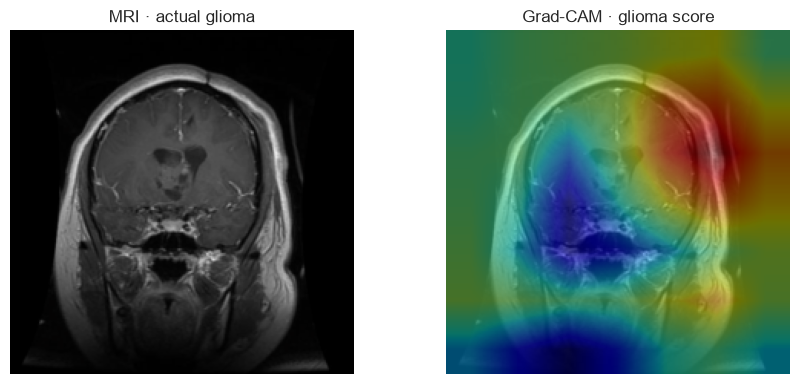

,class,model score (uncalibrated)
0,glioma,0.994584
2,no_tumor,0.003078
1,meningioma,0.001942
3,pituitary,0.000396


In [13]:
def make_gradcam(model, image_tensor, class_index=None):
    layer = model.features[-1]
    captured = {}
    handle = layer.register_forward_hook(lambda module, inputs, output: captured.__setitem__("activation", output))
    model.eval(); model.zero_grad(set_to_none=True)
    x = image_tensor.unsqueeze(0).to(DEVICE).requires_grad_(True)
    logits = model(x)
    target = int(logits.argmax(1).item()) if class_index is None else int(class_index)
    activation = captured["activation"]
    gradient = torch.autograd.grad(logits[0, target], activation, retain_graph=False)[0]
    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activation).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min(); cam = cam / cam.max().clamp_min(1e-8)
    handle.remove()
    return cam.detach().cpu().numpy(), target, torch.softmax(logits.detach(), dim=1)[0].cpu().numpy()

sample_index = 0
sample_image, sample_label = val_cls[sample_index]
cam, cam_class, sample_scores = make_gradcam(classifier, sample_image)
image_display = (sample_image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(image_display); axes[0].set_title(f"MRI · actual {CLASSES[int(sample_label)]}"); axes[0].axis("off")
axes[1].imshow(image_display); axes[1].imshow(cam, cmap="jet", alpha=.45, vmin=0, vmax=1)
axes[1].set_title(f"Grad-CAM · {CLASSES[cam_class]} score"); axes[1].axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"class": CLASSES, "model score (uncalibrated)": sample_scores}).sort_values("model score (uncalibrated)", ascending=False))

## 6. Train every segmentation architecture

Both segmenters learn a binary tumor-region mask. The objective combines weighted binary cross-entropy, soft Dice loss, and focal Tversky loss to emphasize overlap and false-negative control. Thresholds are selected from validation predictions only. Paired image/mask augmentation is implemented by the project's `SegmentationDataset`.

In [14]:
def segmentation_loss(logits, targets, bce_loss):
    probabilities = torch.sigmoid(logits)
    axes = (1, 2, 3)
    intersection = (probabilities * targets).sum(dim=axes)
    predicted = probabilities.sum(dim=axes)
    actual = targets.sum(dim=axes)
    dice_loss = 1 - ((2 * intersection + 1) / (predicted + actual + 1)).mean()
    true_positive = intersection
    false_positive = (probabilities * (1 - targets)).sum(dim=axes)
    false_negative = ((1 - probabilities) * targets).sum(dim=axes)
    tversky = (true_positive + 1) / (true_positive + .35 * false_positive + .65 * false_negative + 1)
    focal_tversky_loss = (1 - tversky).clamp_min(0).pow(.75).mean()
    return .5 * bce_loss(logits, targets) + dice_loss + .35 * focal_tversky_loss

SEGMENTATION_THRESHOLDS = np.arange(.15, .851, .05).round(2).tolist()

@torch.inference_mode()
def validation_threshold_curve(model, loader, thresholds=SEGMENTATION_THRESHOLDS):
    totals = np.zeros(len(thresholds), dtype=np.float64); count = 0
    model.eval()
    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        target = masks.to(DEVICE, non_blocking=True) >= .5
        probabilities = predict_segmentation_probability(model, images, USE_HORIZONTAL_FLIP_TTA).float()
        for index, threshold in enumerate(thresholds):
            prediction = probabilities >= threshold
            intersection = (prediction & target).sum(dim=(1, 2, 3)).float()
            denominator = prediction.sum(dim=(1, 2, 3)).float() + target.sum(dim=(1, 2, 3)).float()
            dice = torch.where(denominator == 0, 1.0, 2 * intersection / denominator.clamp_min(1))
            totals[index] += float(dice.sum().cpu())
        count += int(images.shape[0])
    return {float(t): float(total / max(count, 1)) for t, total in zip(thresholds, totals)}

SEGMENTER_BUILDERS = {"compact_unet": build_compact_unet, "attention_unet": build_attention_unet}
segmentation_runs = {}

def train_segmenter(name, builder, seed):
    set_seed(seed)
    model = builder().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=SEGMENTATION_LR, weight_decay=1e-4)
    bce_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([2.0], device=DEVICE))
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=.5, patience=3, min_lr=1e-5)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
    best_dice, best_threshold, best_state, best_epoch, stale = -1.0, .5, None, 0, 0
    history = []
    for epoch in range(SEGMENTATION_EPOCHS):
        model.train(); loss_sum = 0.0
        for images, masks in tqdm(train_seg_loader, desc=f"{name} epoch {epoch + 1}/{SEGMENTATION_EPOCHS}", leave=False):
            images = images.to(DEVICE, non_blocking=True); masks = masks.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(images); loss = segmentation_loss(logits, masks, bce_loss)
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer); scaler.update(); loss_sum += float(loss.detach())
        curve = validation_threshold_curve(model, val_seg_loader)
        threshold, val_dice = max(curve.items(), key=lambda item: item[1])
        scheduler.step(val_dice)
        record = {"epoch": epoch + 1, "train_loss": loss_sum / max(len(train_seg_loader), 1),
                  "validation_dice": val_dice, "validation_threshold": threshold,
                  "learning_rate": optimizer.param_groups[0]["lr"]}
        history.append(record)
        print(f"{name} epoch {epoch + 1:02d}/{SEGMENTATION_EPOCHS} | loss {record['train_loss']:.4f} | val Dice {val_dice:.4f} | threshold {threshold:.2f}")
        if val_dice > best_dice + 1e-4:
            best_dice, best_threshold = val_dice, threshold
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            best_epoch, stale = epoch + 1, 0
        else:
            stale += 1
            if stale >= SEGMENTATION_PATIENCE:
                print(f"Early stopping. Best epoch: {best_epoch}")
                break
    if best_state is None:
        raise RuntimeError(f"{name} did not produce a validation checkpoint.")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {"state_dict": best_state, "best_dice": best_dice, "threshold": best_threshold,
            "best_epoch": best_epoch, "history": history, "seed": seed}

for model_index, (name, builder) in enumerate(SEGMENTER_BUILDERS.items()):
    segmentation_runs[name] = train_segmenter(name, builder, SEED + model_index)

validation_comparison = pd.DataFrame([
    {"architecture": name, "best validation Dice": run["best_dice"],
     "threshold selected on validation": run["threshold"], "best epoch": run["best_epoch"]}
    for name, run in segmentation_runs.items()
]).sort_values("best validation Dice", ascending=False)
display(validation_comparison)
best_segmenter_name = validation_comparison.iloc[0]["architecture"]
print("Selected using validation Dice only:", best_segmenter_name)

compact_unet epoch 1/20:   0%|          | 0/1034 [00:00<?, ?it/s]

compact_unet epoch 01/20 | loss 1.3741 | val Dice 0.3467 | threshold 0.85


compact_unet epoch 2/20:   0%|          | 0/1034 [00:00<?, ?it/s]

compact_unet epoch 02/20 | loss 0.9864 | val Dice 0.4519 | threshold 0.55


compact_unet epoch 3/20:   0%|          | 0/1034 [00:00<?, ?it/s]

...

attention_unet epoch 19/20 | loss 0.2341 | val Dice 0.8795 | threshold 0.55


attention_unet epoch 20/20:   0%|          | 0/1034 [00:00<?, ?it/s]

attention_unet epoch 20/20 | loss 0.2290 | val Dice 0.8685 | threshold 0.75


,architecture,best validation Dice,threshold selected on validation,best epoch
1,attention_unet,0.879492,0.55,19
0,compact_unet,0.672150,0.50,19


Selected using validation Dice only: attention_unet


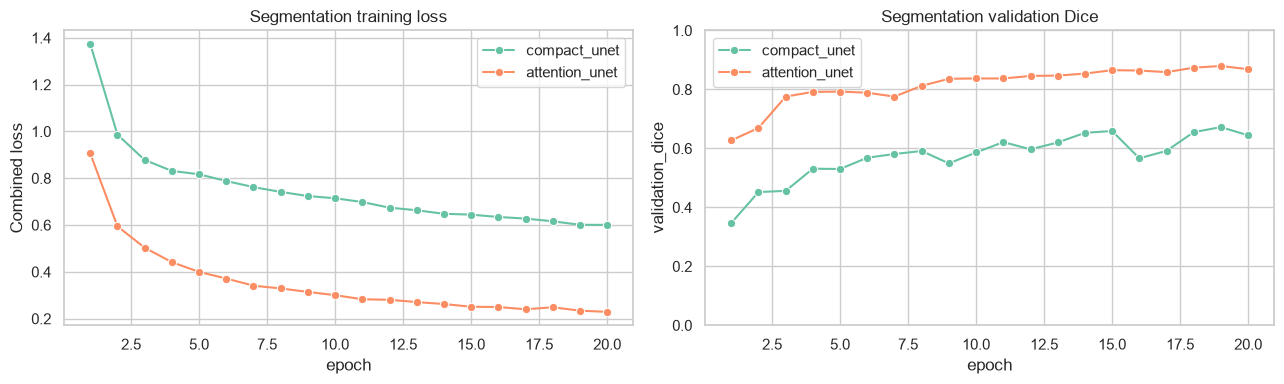

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, run in segmentation_runs.items():
    history = pd.DataFrame(run["history"])
    sns.lineplot(data=history, x="epoch", y="train_loss", marker="o", label=name, ax=axes[0])
    sns.lineplot(data=history, x="epoch", y="validation_dice", marker="o", label=name, ax=axes[1])
axes[0].set_title("Segmentation training loss"); axes[0].set_ylabel("Combined loss")
axes[1].set_title("Segmentation validation Dice"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

fig = px.bar(validation_comparison, x="architecture", y="best validation Dice", color="architecture",
             text_auto=".3f", title="Segmentation model comparison · validation only", range_y=[0, 1])
fig.update_layout(showlegend=False, xaxis_title="Architecture", yaxis_title="Best validation Dice")
fig.show()

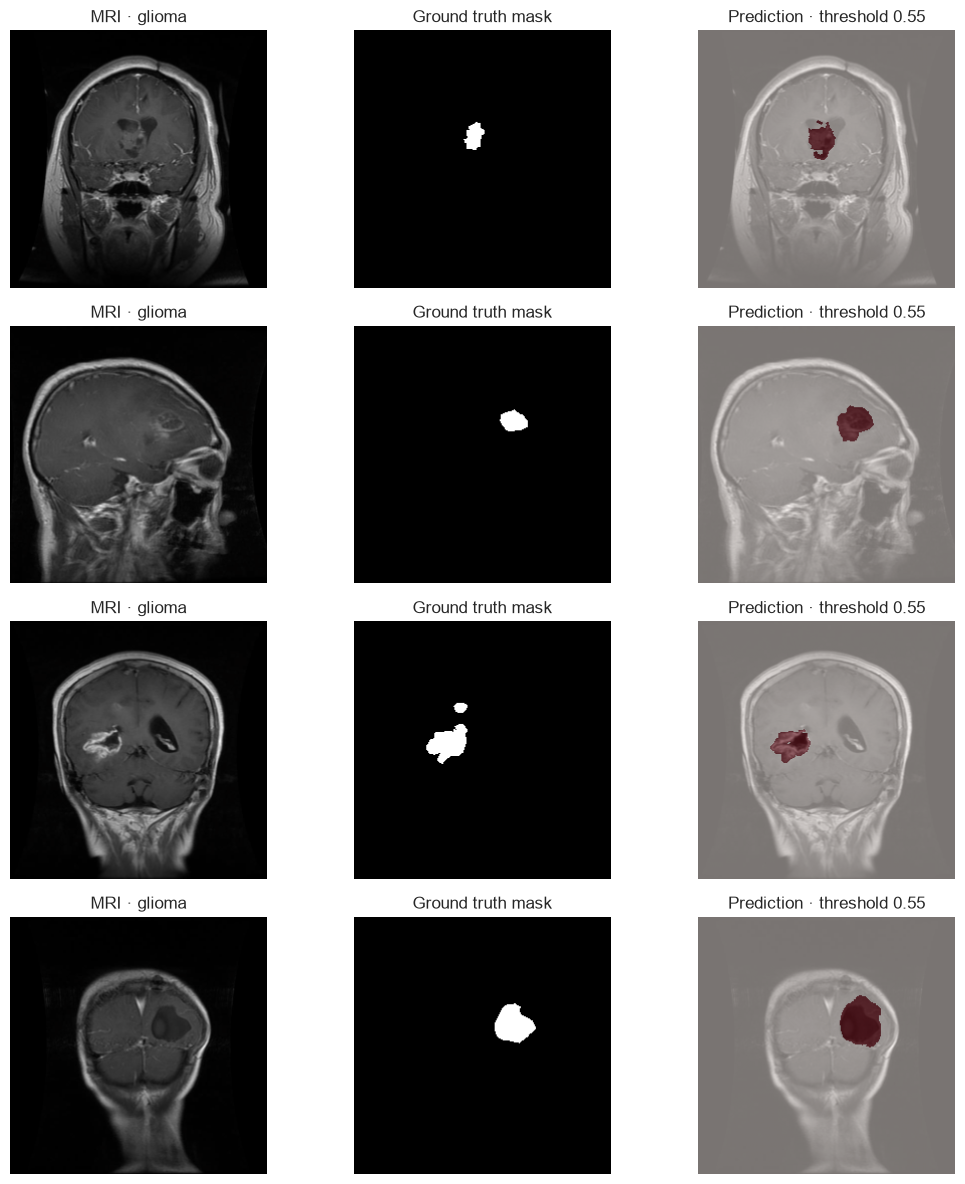

In [16]:
selected_segmenter = SEGMENTER_BUILDERS[best_segmenter_name]().to(DEVICE)
selected_segmenter.load_state_dict(segmentation_runs[best_segmenter_name]["state_dict"])
selected_segmenter.eval()
selected_threshold = float(segmentation_runs[best_segmenter_name]["threshold"])

def denormalize(image_tensor):
    return (image_tensor.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

def show_segmentation_predictions(model, dataset, indices=(0, 1, 2, 3), threshold=selected_threshold):
    fig, axes = plt.subplots(len(indices), 3, figsize=(11, max(3, len(indices) * 3)), squeeze=False)
    model.eval()
    with torch.inference_mode():
        for row_index, index in enumerate(indices):
            image, truth = dataset[index]
            probability = predict_segmentation_probability(model, image.unsqueeze(0).to(DEVICE), USE_HORIZONTAL_FLIP_TTA)[0, 0].cpu().numpy()
            prediction = probability >= threshold
            shown = denormalize(image)
            axes[row_index, 0].imshow(shown); axes[row_index, 0].set_title(f"MRI · {dataset.rows[index]['label']}")
            axes[row_index, 1].imshow(truth[0], cmap="gray", vmin=0, vmax=1); axes[row_index, 1].set_title("Ground truth mask")
            axes[row_index, 2].imshow(shown); axes[row_index, 2].imshow(prediction, cmap="Reds", alpha=.48, vmin=0, vmax=1)
            axes[row_index, 2].set_title(f"Prediction · threshold {threshold:.2f}")
            for ax in axes[row_index]: ax.axis("off")
    plt.tight_layout(); plt.show()

show_segmentation_predictions(selected_segmenter, val_seg, indices=tuple(range(min(4, len(val_seg)))))

## 7. Final held-out evaluation

Training, checkpoint selection, and segmentation threshold selection have used only the training and validation splits. The next cell evaluates the fixed classifier and both fixed segmenter candidates on the test split for reporting. Review the metrics once; do not use them to tune epochs, thresholds, or model settings.

Classification reports accuracy, macro precision/recall/F1, one-vs-rest macro ROC-AUC, and the confusion matrix. Segmentation reports mean per-image Dice and IoU overall and by class. Dice is twice the overlap divided by predicted plus true area; IoU is overlap divided by union. Empty/empty masks score 1; a non-empty prediction against an empty target scores 0.

In [17]:
def evaluate_classifier(model, loader):
    y_true, probabilities, _ = collect_classification_outputs(model, loader)
    y_pred = probabilities.argmax(axis=1)
    report = classification_report(y_true, y_pred, labels=range(len(CLASSES)), target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    try:
        macro_auc = roc_auc_score(y_true, probabilities, labels=range(len(CLASSES)), multi_class="ovr", average="macro")
    except ValueError:
        macro_auc = None
    result = {
        "sample_count": int(len(y_true)), "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(report["macro avg"]["precision"]),
        "macro_recall": float(report["macro avg"]["recall"]),
        "macro_f1": float(report["macro avg"]["f1-score"]),
        "roc_auc_ovr_macro": None if macro_auc is None else float(macro_auc),
        "per_class": {name: {"precision": float(report[name]["precision"]), "recall": float(report[name]["recall"]),
                              "f1": float(report[name]["f1-score"]), "support": int(report[name]["support"])} for name in CLASSES},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=range(len(CLASSES))).tolist(),
        "class_order": list(CLASSES),
        "interpretation": "Scores are uncalibrated model scores; results only measure this image-level BRISC split."
    }
    return result, y_true, y_pred, probabilities

@torch.inference_mode()
def evaluate_segmenter(model, loader, rows, threshold):
    all_dice, all_iou, per_class = [], [], {name: {"dice": [], "iou": []} for name in CLASSES}
    cursor = 0; model.eval()
    for images, masks in tqdm(loader, desc="Evaluating held-out segmentation", leave=False):
        probabilities = predict_segmentation_probability(model, images.to(DEVICE), USE_HORIZONTAL_FLIP_TTA)
        predictions = probabilities >= threshold
        targets = masks.to(DEVICE) >= .5
        for prediction, target in zip(predictions, targets):
            intersection = int((prediction & target).sum().item())
            predicted_area = int(prediction.sum().item()); target_area = int(target.sum().item())
            union = predicted_area + target_area - intersection
            dice = (2 * intersection / (predicted_area + target_area)) if predicted_area + target_area else 1.0
            iou = (intersection / union) if union else 1.0
            label = rows[cursor]["label"]
            all_dice.append(dice); all_iou.append(iou)
            per_class[label]["dice"].append(dice); per_class[label]["iou"].append(iou)
            cursor += 1
    return {
        "sample_count": len(all_dice), "mean_per_image_dice": float(np.mean(all_dice)),
        "mean_per_image_iou": float(np.mean(all_iou)), "threshold_selected_on_validation": float(threshold),
        "horizontal_flip_tta": bool(USE_HORIZONTAL_FLIP_TTA),
        "per_class": {name: {metric: float(np.mean(values[metric])) for metric in ("dice", "iou") if values[metric]}
                      | {"support": len(values["dice"])} for name, values in per_class.items() if values["dice"]},
        "empty_mask_convention": "Empty/empty scores 1.0; empty truth with non-empty prediction scores 0.0.",
        "mask_semantics": "Binary tumor-region mask; it does not identify tumor subtype or make a diagnosis."
    }

classifier_test_metrics, y_test, y_test_pred, test_probabilities = evaluate_classifier(classifier, test_cls_loader)
segmentation_test_metrics = {}
for name, run in segmentation_runs.items():
    model = SEGMENTER_BUILDERS[name]().to(DEVICE)
    model.load_state_dict(run["state_dict"]); model.eval()
    segmentation_test_metrics[name] = evaluate_segmenter(model, test_seg_loader, test_seg.rows, run["threshold"])
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

test_summary = pd.DataFrame([
    {"Task": "Classification", "Model": "MobileNetV3-Small", "Test images": classifier_test_metrics["sample_count"],
     "Accuracy": classifier_test_metrics["accuracy"], "Macro F1": classifier_test_metrics["macro_f1"],
     "Mean Dice": np.nan, "Mean IoU": np.nan},
    *[{"Task": "Segmentation", "Model": name, "Test images": metrics["sample_count"],
       "Accuracy": np.nan, "Macro F1": np.nan, "Mean Dice": metrics["mean_per_image_dice"], "Mean IoU": metrics["mean_per_image_iou"]}
      for name, metrics in segmentation_test_metrics.items()]
])
display(test_summary.style.format({"Accuracy": "{:.2%}", "Macro F1": "{:.2%}", "Mean Dice": "{:.2%}", "Mean IoU": "{:.2%}"}, na_rep="—"))

Evaluating held-out segmentation:   0%|          | 0/248 [00:00<?, ?it/s]

Evaluating held-out segmentation:   0%|          | 0/248 [00:00<?, ?it/s]

,Task,Model,Test images,Accuracy,Macro F1,Mean Dice,Mean IoU
0,Classification,MobileNetV3-Small,992,85.38%,84.11%,—,—
1,Segmentation,compact_unet,992,—,—,65.46%,57.02%
2,Segmentation,attention_unet,992,—,—,84.86%,78.41%


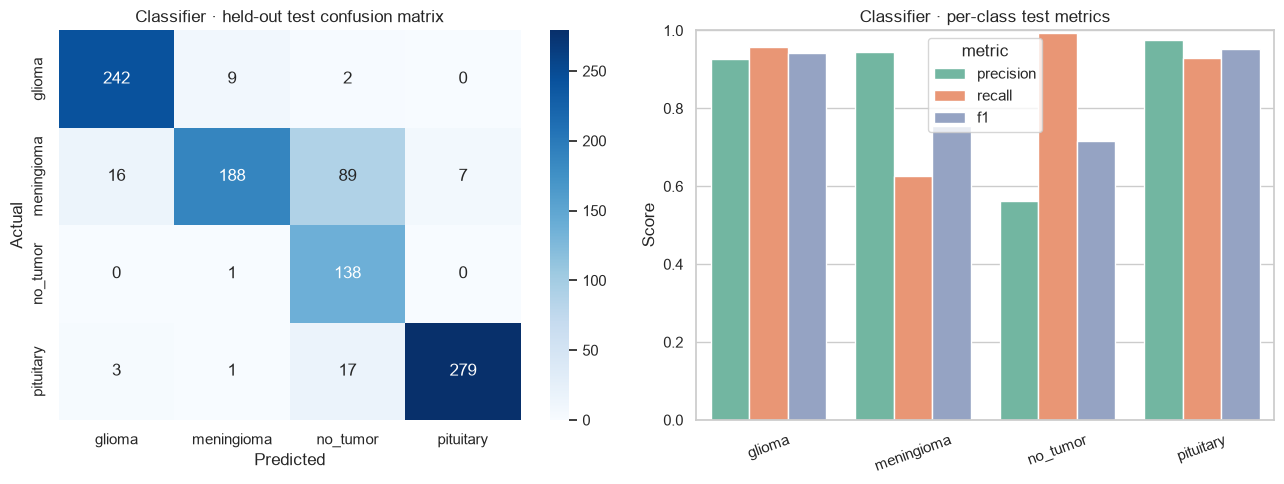

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(np.asarray(classifier_test_metrics["confusion_matrix"]), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set(title="Classifier · held-out test confusion matrix", xlabel="Predicted", ylabel="Actual")
class_frame = pd.DataFrame(classifier_test_metrics["per_class"]).T.reset_index(names="class")
class_long = class_frame.melt(id_vars="class", value_vars=["precision", "recall", "f1"], var_name="metric", value_name="score")
sns.barplot(data=class_long, x="class", y="score", hue="metric", ax=axes[1])
axes[1].set(title="Classifier · per-class test metrics", xlabel="", ylabel="Score", ylim=(0, 1)); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

fig = go.Figure()
for index, label in enumerate(CLASSES):
    binary_true = (y_test == index).astype(int)
    if binary_true.min() == binary_true.max():
        continue
    fpr, tpr, _ = roc_curve(binary_true, test_probabilities[:, index])
    class_auc = auc(fpr, tpr)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", name=f"{label} (AUC {class_auc:.3f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="Chance", line={"dash": "dash", "color": "gray"}))
fig.update_layout(title="One-vs-rest ROC curves · held-out test split", xaxis_title="False positive rate", yaxis_title="True positive rate", width=760, height=520)
fig.show()

In [19]:
seg_rows = []
for name, metrics in segmentation_test_metrics.items():
    for label, values in metrics["per_class"].items():
        seg_rows.append({"model": name, "class": label, "Dice": values["dice"], "IoU": values["iou"], "support": values["support"]})
seg_per_class = pd.DataFrame(seg_rows)
fig = px.bar(seg_per_class, x="class", y="Dice", color="model", barmode="group", text_auto=".2%",
             category_orders={"class": classes}, title="Segmentation · mean per-image Dice by class")
fig.update_layout(yaxis_tickformat=".0%", yaxis_range=[0, 1], xaxis_title="Image-level class", yaxis_title="Mean Dice")
fig.show()
display(seg_per_class)

,model,class,Dice,IoU,support
0,compact_unet,glioma,0.486008,0.395988,253
1,compact_unet,meningioma,0.721598,0.618090,300
2,compact_unet,no_tumor,0.625899,0.625899,139
3,compact_unet,pituitary,0.742930,0.643389,300
4,attention_unet,glioma,0.697625,0.601873,253
5,attention_unet,meningioma,0.885731,0.833608,300
6,attention_unet,no_tumor,0.985612,0.985612,139
7,attention_unet,pituitary,0.875209,0.795028,300


## 8. Save model packages and reports

The output directory contains a MobileNetV3-Small classifier package and both segmentation candidate packages. Each contains a PyTorch state dictionary plus `model.json` metadata and a training record. The segmentation candidate chosen by **validation Dice** is recorded separately; the app's existing active model is left untouched.

To try a trained model in the app later, back up the current package first, then copy the **contents** of the chosen package folder (keep `model.json` and `model.pt` together) into `assets/models/classifier` or `assets/models/segmenter`. Restart the API and check the model status. A ready status confirms packaging, not medical validity.

In [20]:
PACKAGE_ROOT = RUN_DIR / "model_packages"
classifier_dir = PACKAGE_ROOT / "classifier"
classifier_dir.mkdir(parents=True)
torch.save(best_classifier_state, classifier_dir / "model.pt")
(classifier_dir / "model.json").write_text(json.dumps({
    "task": "classifier", "name": "Notebook MobileNetV3-Small", "architecture": "mobilenet_v3_small",
    "input_size": CLASSIFIER_SIZE, "weights_file": "model.pt", "classes": list(CLASSES),
    "mean": [.485, .456, .406], "std": [.229, .224, .225],
    "class_score_semantics": "uncalibrated_model_scores"
}, indent=2), encoding="utf-8")
(classifier_dir / "training.json").write_text(json.dumps({
    "seed": SEED, "epochs_requested": CLASSIFIER_EPOCHS, "best_validation_accuracy": best_val_accuracy,
    "train_images": len(train_cls), "validation_images": len(val_cls), "device": str(DEVICE),
    "history": history_classifier, "warning": "Test metrics are stored separately; test data did not select this checkpoint."
}, indent=2), encoding="utf-8")

for name, run in segmentation_runs.items():
    model_dir = PACKAGE_ROOT / name; model_dir.mkdir(parents=True)
    torch.save(run["state_dict"], model_dir / "model.pt")
    (model_dir / "model.json").write_text(json.dumps({
        "task": "segmenter", "name": f"Notebook {name}", "architecture": name,
        "input_size": SEGMENTATION_SIZE, "weights_file": "model.pt", "threshold": run["threshold"],
        "horizontal_flip_tta": USE_HORIZONTAL_FLIP_TTA, "mean": [.485, .456, .406], "std": [.229, .224, .225],
        "mask_semantics": "binary predicted tumor-region mask; not a diagnosis"
    }, indent=2), encoding="utf-8")
    (model_dir / "training.json").write_text(json.dumps({
        "seed": run["seed"], "best_epoch": run["best_epoch"], "epochs_requested": SEGMENTATION_EPOCHS,
        "best_validation_dice": run["best_dice"], "threshold_selected_on_validation": run["threshold"],
        "train_rows": len(train_seg), "validation_rows": len(val_seg), "device": str(DEVICE), "history": run["history"],
        "warning": "Test metrics are stored separately; neither the checkpoint nor threshold was selected using test data."
    }, indent=2), encoding="utf-8")

REPORT_DIR = RUN_DIR / "evaluations"; REPORT_DIR.mkdir()
(REPORT_DIR / "classifier_test.json").write_text(json.dumps(classifier_test_metrics, indent=2), encoding="utf-8")
for name, metrics in segmentation_test_metrics.items():
    (REPORT_DIR / f"{name}_test.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
history_cls_df.to_csv(RUN_DIR / "classifier_training_history.csv", index=False)
for name, run in segmentation_runs.items():
    pd.DataFrame(run["history"]).to_csv(RUN_DIR / f"{name}_training_history.csv", index=False)

summary = {
    "run_id": RUN_ID, "project_root": str(PROJECT_ROOT), "manifest": str(MANIFEST_PATH),
    "selected_segmenter_by_validation": best_segmenter_name,
    "test_metrics": {"classifier": classifier_test_metrics, "segmenters": segmentation_test_metrics},
    "limitation": "BRISC has no patient identifiers; exact decoded-image deduplication does not prove patient-level independence or external generalization. Not for clinical use."
}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved model packages:", PACKAGE_ROOT)
print("Saved evaluation reports:", REPORT_DIR)
print("Run summary:", RUN_DIR / "summary.json")

Saved model packages: D:\BTS\notebooks\outputs\20261027_213449_214091\model_packages
Saved evaluation reports: D:\BTS\notebooks\outputs\20261027_213449_214091\evaluations
Run summary: D:\BTS\notebooks\outputs\20261027_213449_214091\summary.json


## 9. How to interpret the results

- **Accuracy** is the fraction of correctly classified images. **Macro F1** computes F1 separately for each class and averages the four values equally, so the larger classes do not dominate the summary.
- **ROC-AUC (one-vs-rest)** measures ranking separation for each class against the rest. It does not mean scores are calibrated probabilities.
- **Dice** and **IoU** compare predicted and true pixel regions. They do not measure tumor subtype, grade, or clinical significance.
- A good validation/test result on this dataset is not evidence that a new image from another site will be classified correctly. BRISC has no patient IDs and this notebook does not perform external validation.
- Use the example galleries to inspect failure modes. Do not choose a checkpoint or tune the mask threshold from the test results.

## Troubleshooting

1. **Manifest or image not found:** confirm `data/manifests/brisc.csv` and the extracted `data/datasets/brisc2025/` folder exist. The BRISC archive must be extracted while preserving its `classification_task` and `segmentation_task` folders.
2. **Notebook imports fail:** ensure the notebook kernel is the project `.venv` interpreter and run the setup command in Section 1.
3. **CUDA out-of-memory:** lower `SEGMENTATION_BATCH_SIZE` to 2 or 1; if needed reduce `SEGMENTATION_SIZE` to 192. Keep the chosen input size in model metadata.
4. **CPU training is slow:** lower epoch limits for a smoke run, but do not report short-run results as the project benchmark. Restore the intended training settings for a real run.
5. **App model files:** the notebook saves versioned packages under its run folder. It never overwrites the active `assets/models/classifier` or `assets/models/segmenter` packages automatically.

The dataset is BRISC 2025 v3. Follow the dataset's license and citation terms when sharing data or results.